In [26]:
from dotenv import load_dotenv
load_dotenv()

True

In [36]:
from langgraph.graph import StateGraph, START, END
from langchain_ollama import ChatOllama
from pydantic import BaseModel
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver


In [28]:
class MailState(BaseModel):
    query: str = ""
    draft: str = ""
    human_feedback: str = ""
    final_response: str = ""

In [29]:
llm = ChatOllama(model="qwen3:1.7b")

In [ ]:
def DraftEmail(state: MailState):
    prompt = f"Write a professional email for the following query: {state.query}"
    response = llm.invoke(prompt).content
    return {"draft": response}


def GetHumanFeedback(state: MailState):
    feedback = interrupt({
        "draft_email": state.draft,
        "question": "Do you want to make any changes to the draft email? If yes, please provide your feedback. If no, please type 'No changes needed'.",
    })
    fb = (feedback or "").strip().lower()
    if fb in ["no changes needed", "no", "none", "nothing"]:
        return {"human_feedback": "no changes needed"}   
    return {"human_feedback": feedback}


def FinalizeEmail(state: MailState):
    if state.human_feedback == "no changes needed":
        return {"final_response": state.draft}
    prompt = (
        f"Here is the draft email: {state.draft}. "
        f"The user has provided the following feedback: {state.human_feedback}. "
        "Please revise the draft email accordingly."
    )
    return {"final_response": llm.invoke(prompt).content}

In [31]:
graph_builder = StateGraph(MailState)

graph_builder.add_node("draft", DraftEmail)
graph_builder.add_node("feedback", GetHumanFeedback)
graph_builder.add_node("finalize", FinalizeEmail) 


graph_builder.add_edge(START, "draft")
graph_builder.add_edge("draft", "feedback")
graph_builder.add_edge("feedback", "finalize")
graph_builder.add_edge("finalize", END)

graph = graph_builder.compile(checkpointer=InMemorySaver())

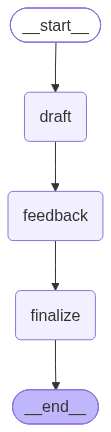

In [32]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [33]:
config = {"configurable": {"thread_id": "2"}}

In [34]:
res = graph.invoke({"query": "I want to write an email to my manager requesting a day off next week."}, config=config)

In [35]:
res

{'query': 'I want to write an email to my manager requesting a day off next week.',
 'draft': '**Subject:** Request for Day Off Next Week  \n\n**Dear [Manager\'s Name],**  \n\nI hope this email finds you well. I am writing to kindly request a day off from [specific date or range, e.g., "Monday, April 10th to Tuesday, April 11th"] to accommodate [brief explanation, e.g., "personal matters"].\n\nI understand the importance of maintaining productivity and would appreciate your consideration of this request. If there are any preferences or alternative dates you would like me to propose, please let me know.  \n\nThank you for your time and support. I look forward to your approval.  \n\nBest regards,  \n[Your Full Name]  \n[Your Job Title]  \n[Your Contact Information]  \n\n---  \n*Note: Customize the dates, reason, and details to fit your specific situation.*',
 '__interrupt__': [Interrupt(value={'draft_email': '**Subject:** Request for Day Off Next Week  \n\n**Dear [Manager\'s Name],**  \n

In [37]:
res = graph.invoke(Command(resume="this is to long i want short one"), config=config)

In [38]:
res

{'query': 'I want to write an email to my manager requesting a day off next week.',
 'draft': '**Subject:** Request for Day Off Next Week  \n\n**Dear [Manager\'s Name],**  \n\nI hope this email finds you well. I am writing to kindly request a day off from [specific date or range, e.g., "Monday, April 10th to Tuesday, April 11th"] to accommodate [brief explanation, e.g., "personal matters"].\n\nI understand the importance of maintaining productivity and would appreciate your consideration of this request. If there are any preferences or alternative dates you would like me to propose, please let me know.  \n\nThank you for your time and support. I look forward to your approval.  \n\nBest regards,  \n[Your Full Name]  \n[Your Job Title]  \n[Your Contact Information]  \n\n---  \n*Note: Customize the dates, reason, and details to fit your specific situation.*',
 'human_feedback': 'this is to long i want short one',
 'final_response': '**Subject:** Request for Day Off  \n**Dear [Manager\'s N

In [39]:
res = graph.invoke(Command(resume="No changes needed"), config=config)

In [41]:
print(res["final_response"])

**Subject:** Request for Day Off  
**Dear [Manager's Name],**  

I hope this email finds you well. I’d like to request a day off from [specific date, e.g., "April 10th"] to handle [brief explanation, e.g., "personal matters"].  

Please let me know if this date works for you.  

Thank you for your support.  

Best regards,  
[Your Full Name]  
[Your Job Title]  
[Your Contact Info]  

---  
*Note: Customize dates and reason as needed.*
